# Universidad Externado de Colombia · Visualización 1
## Proyecto 3: Narrativa Visual Integrada — Componente Analítico en Python
### Radiografía de la Informalidad Laboral en Colombia: La Paradoja de los Nuevos Profesionales (GEIH 2026)

**Autores:** Julián Steven Duarte & Julián Camilo Jiménez  
**Docentes:** Adriana Pineda Barón & Paola Moreno  
**Asignatura:** Visualización I — Maestría / Especialización en Ciencia de Datos  
**Fuente Oficial:** Gran Encuesta Integrada de Hogares (GEIH 2026) — DANE  
**Fecha:** Noviembre de 2026  

---


## 1. Encuadre Estratégico, Audiencia Ciudadana y Pregunta Analítica

### 1.1. Audiencia Ciudadana Específica
A diferencia de los proyectos previos (diseñados para directivos del Ministerio o analistas de investigación), este análisis se comunica a una **audiencia ciudadana claramente delimitada**:
> **Audiencia:** Jóvenes egresados, técnicos, tecnólogos y profesionales de 18 a 28 años en Colombia que ingresan al mercado de trabajo o buscan su primera oportunidad laboral digna.

### 1.2. Necesidad de Comprensión
Durante décadas, a las familias colombianas se les vendió la promesa de que la educación superior era la llave de oro para garantizar estabilidad económica y seguridad social. Sin embargo, hoy miles de egresados se enfrentan a una frustrante realidad: salarios deprimidos, contratos por prestación de servicios sin cobertura de salud/pensión o subempleo informal. 

Esta audiencia necesita responder una pregunta vital:  
> **Pregunta Analítica Central:** *¿Por qué haber cursado educación superior en Colombia ya no es un pasaporte asegurado a la formalidad laboral, y de qué manera la región geográfica y el género condicionan las probabilidades reales de conseguir un empleo digno?*

### 1.3. La Gran Idea
> **La Gran Idea:** *"En Colombia, más de 6 de cada 10 graduados con educación superior y técnica están atrapados en la informalidad o el rebusque profesional (61.3%). Esta trampa de la precarización calificada no es uniforme: se agrava drásticamente en la periferia del país (llegando al 75.7% en departamentos como Guaviare) y oculta una grave desigualdad de género, donde miles de mujeres ni siquiera logran ingresar al mercado al estar confinadas al cuidado no remunerado. Comprender esta evidencia empodera a los jóvenes para tomar decisiones estratégicas de empleabilidad y exige trascender los subsidios asistenciales hacia incentivos de formalización productiva."*

---


## 2. Preparación del Entorno, Paleta Cromática y Principios Gestalt

Siguiendo las pautas pedagógicas del curso, establecemos un entorno reproducible, sobrio y accesible:
1. **Paleta Semántica Accesible:**
   - **Rojo Coral / Terracota (`#E11D48`):** Color semántico reservado estrictamente para alertar focos críticos (el 61.3% de informalidad en educación superior o departamentos en emergencia).
   - **Azul Institucional (`#2563EB`):** Tono analítico neutro para el empleo formal y comparaciones de referencia.
   - **Púrpura / Violeta (`#9333EA`):** Para desagregación de género femenino con adecuado contraste WCAG AA.
   - **Gris Pizarra (`#94A3B8`):** Para categorías de contexto secundario.
2. **Principios Gestalt:**
   - **Similitud:** Las categorías basales comparten color gris neutro, mientras el foco narrativo resalta en color cálido.
   - **Proximidad:** Disposición en barras horizontales con etiquetas numéricas directas para evitar saltos oculares entre el gráfico y los ejes.
   - **Eliminación de Ruido (*Chartjunk*):** Supresión de bordes innecesarios, líneas de fondo tenues y tipografía legible.


In [1]:
# 1. IMPORTACIÓN DE LIBRERÍAS Y CONFIGURACIÓN ESTÉTICA
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import plotly.graph_objects as go

# Configuración estética global de Matplotlib y Seaborn
plt.rcParams['font.sans-serif'] = 'Segoe UI, DejaVu Sans, Arial'
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['figure.dpi'] = 150
sns.set_theme(style="whitegrid", font='Segoe UI')

print("✓ Entorno analítico configurado correctamente con Seaborn y Plotly.")


✓ Entorno analítico configurado correctamente con Seaborn y Plotly.


## 3. Carga y Auditoría de Datos (GEIH 2026 - DANE)

Cargamos los datos consolidados a partir de los microdatos oficiales de la GEIH 2026 (primer semestre: Enero a Junio), aplicando el factor de expansión poblacional `FEX_C18` del Censo 2018 para proyectar de forma matemáticamente exacta al universo de trabajadores colombianos.


In [2]:
# 2. CARGA DE TABLAS ANALÍTICAS PREPARADAS
DATOS_DIR = os.path.join("..", "Datos")

df_dep = pd.read_csv(os.path.join(DATOS_DIR, "geih_2026_departamentos.csv"))
df_edu_edad = pd.read_csv(os.path.join(DATOS_DIR, "geih_2026_educacion_edad.csv"))
df_sex_edu = pd.read_csv(os.path.join(DATOS_DIR, "geih_2026_sexo_educacion.csv"))
df_m = pd.read_csv(os.path.join(DATOS_DIR, "geih_2026_tendencia_mensual.csv"))

print(f"✓ Departamentos cargados: {len(df_dep)} registros.")
print(f"✓ Educación x Edad: {len(df_edu_edad)} cruces.")
print(f"✓ Sexo x Educación: {len(df_sex_edu)} cruces.")
print(f"✓ Tendencia Mensual: {len(df_m)} meses evaluados (Enero-Junio 2026).")


✓ Departamentos cargados: 33 registros.
✓ Educación x Edad: 14 cruces.
✓ Sexo x Educación: 10 cruces.
✓ Tendencia Mensual: 6 meses evaluados (Enero-Junio 2026).


In [3]:
# Visualizar los primeros registros de la tabla departamental
df_dep.head()


,Nombre_Departamento,FEX_Ocupado,FEX_Informal,Tasa_Informalidad
0,Guaviare,5.872296e+05,4.446201e+05,75.714876
1,Casanare,6.744371e+05,4.488302e+05,66.548853
2,Bogotá D.C.,3.727144e+06,2.388372e+06,64.080478
3,Cundinamarca,2.133289e+06,1.329086e+06,62.302218
4,Nariño,3.003106e+06,1.865681e+06,62.125040


## 4. Visualizaciones Estáticas con Seaborn

Desarrollamos visualizaciones diseñadas para responder progresivamente a la pregunta analítica ciudadana:
1. **La Paradoja Educativa:** ¿Cómo se comporta la informalidad según el nivel educativo alcanzado?
2. **La Brecha de Género:** ¿Cómo impacta la desigualdad en hombres y mujeres a lo largo de su formación?
3. **Trayectoria Temporal:** ¿La informalidad se redujo o empeoró durante el primer semestre de 2026?


### 4.1. Visualización Estática 1: La Paradoja de la Educación Superior en Colombia
**Objetivo Analítico:** Demostrar empíricamente que tener educación superior o secundaria no protege de la informalidad, presentando tasas superiores al 61% frente a la primaria básica (52.4%).


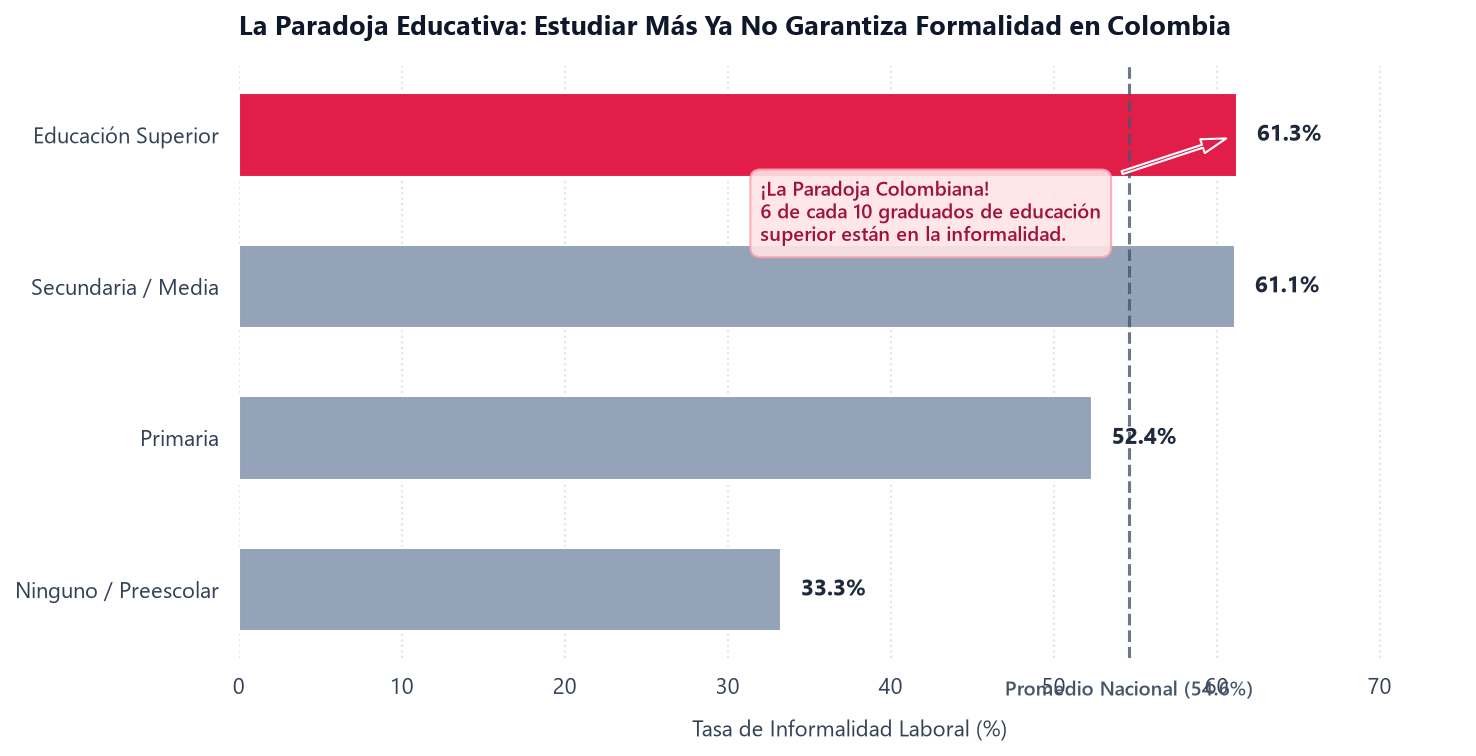

In [4]:
# GRÁFICO 1: LA PARADOJA EDUCATIVA EN COLOMBIA (SEABORN)

# Agrupación y cálculo consolidado
df_edu_tot = df_sex_edu.groupby("Nivel Educativo").agg({
    "FEX_Ocupado": "sum",
    "FEX_Informal": "sum"
}).reset_index()
df_edu_tot = df_edu_tot[df_edu_tot["Nivel Educativo"] != "Sin informació"].copy()
df_edu_tot["Tasa_Informalidad"] = (df_edu_tot["FEX_Informal"] / df_edu_tot["FEX_Ocupado"]) * 100
df_edu_tot = df_edu_tot.sort_values(by="Tasa_Informalidad", ascending=True)

# Construcción visual
fig, ax = plt.subplots(figsize=(10, 5.2))
colores = ["#94A3B8" if edu != "Educación Superior" else "#E11D48" for edu in df_edu_tot["Nivel Educativo"]]

bars = ax.barh(df_edu_tot["Nivel Educativo"], df_edu_tot["Tasa_Informalidad"], color=colores, height=0.55)

# Etiquetas directas de datos
for bar in bars:
    w = bar.get_width()
    y = bar.get_y() + bar.get_height() / 2
    ax.text(w + 1.2, y, f"{w:.1f}%", va='center', ha='left', fontsize=11, fontweight='bold', color="#1E293B")

# Línea de referencia nacional (54.64%)
ax.axvline(54.64, color="#475569", linestyle="--", linewidth=1.5, alpha=0.8)
ax.text(54.64, -0.6, "Promedio Nacional (54.6%)", ha="center", va="top", fontsize=9.5, fontweight="semibold", color="#475569")

# Anotación explicativa ciudadana
ax.annotate(
    "¡La Paradoja Colombiana!\n6 de cada 10 graduados de educación\nsuperior están en la informalidad.",
    xy=(61.26, 3), xytext=(32, 2.3),
    arrowprops=dict(facecolor="#E11D48", shrink=0.08, width=1.5, headwidth=7),
    fontsize=9.5, fontweight="semibold", color="#9F1239",
    bbox=dict(boxstyle="round,pad=0.5", facecolor="#FFE4E6", edgecolor="#FDA4AF", alpha=0.9)
)

ax.set_title("La Paradoja Educativa: Estudiar Más Ya No Garantiza Formalidad en Colombia", fontsize=13, fontweight='bold', color="#0F172A", pad=15, loc='left')
ax.set_xlabel("Tasa de Informalidad Laboral (%)", fontsize=10.5, color="#334155", labelpad=10)
ax.set_ylabel("", fontsize=10)
ax.set_xlim(0, 75)
ax.tick_params(colors="#334155", labelsize=10.5)
sns.despine(left=True, bottom=True)
ax.xaxis.grid(True, linestyle=":", alpha=0.6, color="#CBD5E1")
ax.yaxis.grid(False)

plt.tight_layout()
plt.show()


**Interpretación Humana y Ciudadana (Gráfico 1):**
1. **El título ya no es un escudo protector:** Los trabajadores con **Educación Superior registran una informalidad del 61.26%**, cifra prácticamente idéntica a quienes tienen secundaria (61.14%) y considerablemente mayor a quienes solo cursaron primaria (52.37%).
2. **¿Por qué ocurre esto?** En el mercado colombiano, miles de jóvenes profesionales egresan anualmente hacia un ecosistema empresarial que no genera suficientes plazas contractuales formales. Para subsistir, los graduados deben recurrir a contratos por prestación de servicios precarios, consultorías independientes sin cotización integral o emprendimientos de subsistencia.


### 4.2. Visualización Estática 2: Brecha de Género en la Ocupación Informal
**Objetivo Analítico:** Visibilizar la disparidad entre hombres y mujeres a lo largo de todos los peldaños educativos, desmontando lecturas simplistas sobre las cifras agregadas.


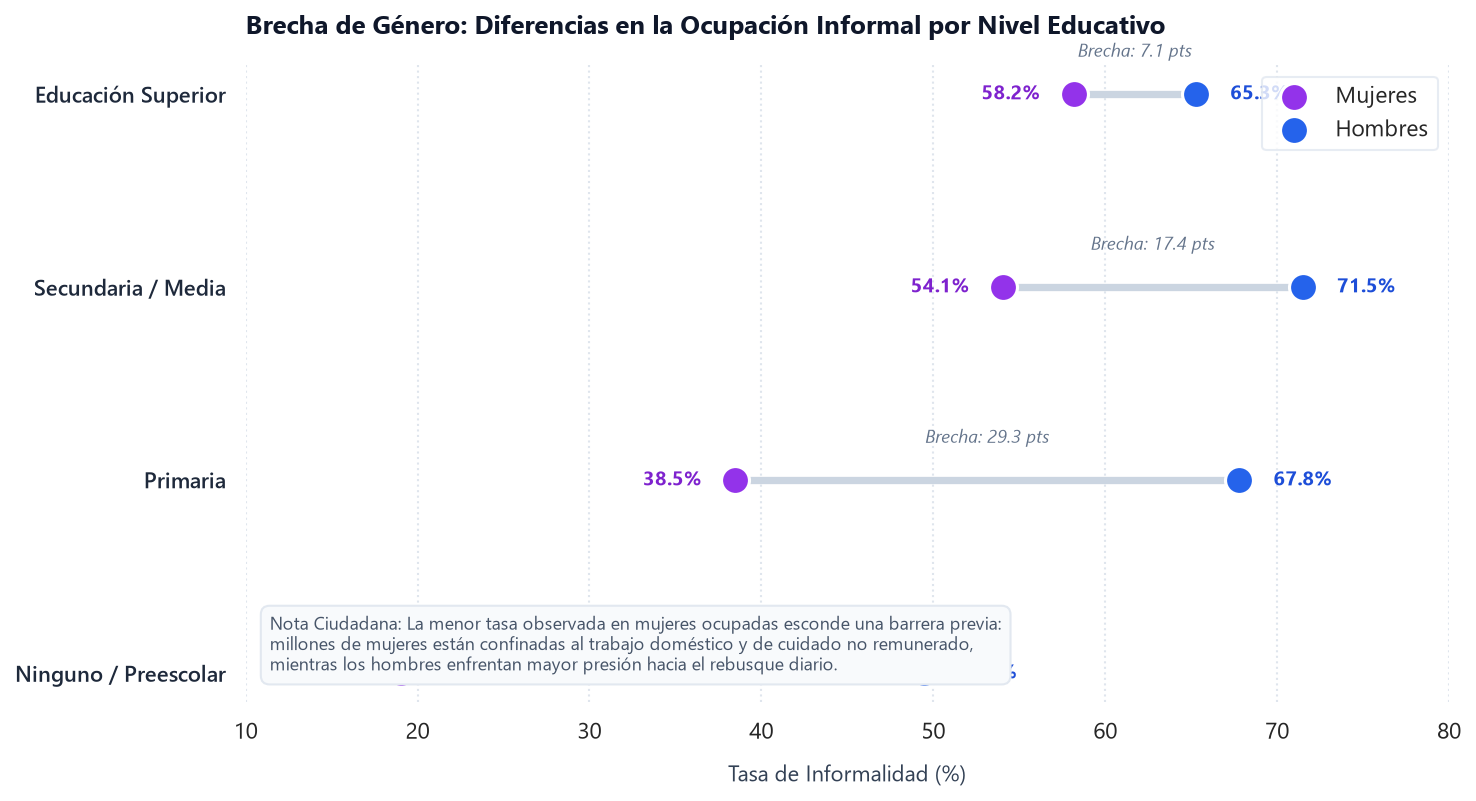

In [5]:
# GRÁFICO 2: BRECHA DE GÉNERO Y NIVEL EDUCATIVO (DUMBBELL CHART - SEABORN)

df_pvt = df_sex_edu[df_sex_edu["Nivel Educativo"] != "Sin informació"].pivot(
    index="Nivel Educativo", columns="Sexo", values="Tasa_Informalidad"
).loc[["Ninguno / Preescolar", "Primaria", "Secundaria / Media", "Educación Superior"]]

fig, ax = plt.subplots(figsize=(10, 5.5))
y_pos = np.arange(len(df_pvt))

# Líneas conectoras
for i, (idx, row) in enumerate(df_pvt.iterrows()):
    ax.plot([row["Mujer"], row["Hombre"]], [i, i], color="#CBD5E1", linewidth=3.5, zorder=1)

# Puntos para Mujeres y Hombres
ax.scatter(df_pvt["Mujer"], y_pos, color="#9333EA", s=180, label="Mujeres", zorder=2, edgecolors="white", linewidths=1.5)
ax.scatter(df_pvt["Hombre"], y_pos, color="#2563EB", s=180, label="Hombres", zorder=2, edgecolors="white", linewidths=1.5)

# Etiquetas numéricas
for i, (idx, row) in enumerate(df_pvt.iterrows()):
    ax.text(row["Mujer"] - 2.0, i, f"{row['Mujer']:.1f}%", va='center', ha='right', fontsize=9.5, fontweight='bold', color="#7E22CE")
    ax.text(row["Hombre"] + 2.0, i, f"{row['Hombre']:.1f}%", va='center', ha='left', fontsize=9.5, fontweight='bold', color="#1D4ED8")
    brecha = row["Hombre"] - row["Mujer"]
    ax.text((row["Mujer"] + row["Hombre"]) / 2, i + 0.22, f"Brecha: {brecha:.1f} pts", va='center', ha='center', fontsize=8.5, color="#64748B", fontstyle='italic')

ax.set_yticks(y_pos)
ax.set_yticklabels(df_pvt.index, fontsize=10.5, fontweight="semibold", color="#1E293B")
ax.set_xlim(10, 80)
ax.set_xlabel("Tasa de Informalidad (%)", fontsize=10.5, color="#334155", labelpad=10)
ax.set_title("Brecha de Género: Diferencias en la Ocupación Informal por Nivel Educativo", fontsize=12.5, fontweight='bold', color="#0F172A", pad=15, loc='left')

ax.text(
    0.02, 0.05,
    "Nota Ciudadana: La menor tasa observada en mujeres ocupadas esconde una barrera previa:\n"
    "millones de mujeres están confinadas al trabajo doméstico y de cuidado no remunerado,\n"
    "mientras los hombres enfrentan mayor presión hacia el rebusque diario.",
    transform=ax.transAxes, fontsize=8.5, color="#475569",
    bbox=dict(boxstyle="round,pad=0.5", facecolor="#F8FAFC", edgecolor="#E2E8F0")
)

ax.legend(loc="upper right", frameon=True, facecolor="white", edgecolor="#E2E8F0")
sns.despine(left=True, bottom=True)
ax.xaxis.grid(True, linestyle=":", alpha=0.6, color="#CBD5E1")
ax.yaxis.grid(False)

plt.tight_layout()
plt.show()


**Interpretación Humana y Ciudadana (Gráfico 2):**
1. **La brecha persiste en los más formados:** Entre egresados de educación superior, los hombres presentan una tasa de informalidad del **65.3%**, mientras que en las mujeres ocupadas es del **58.2%**.
2. **Cuidado no remunerado vs. rebusque obligado:** La brecha no indica que las mujeres disfruten de mejores condiciones. La literatura laboral y las estadísticas de la GEIH confirman que las mujeres enfrentan una **barrera de entrada**: una proporción masiva de mujeres se dedica al cuidado familiar no remunerado. Los hombres que ingresan al mercado, en cambio, deben aceptar cualquier ocupación precaria para garantizar el sustento del hogar.


### 4.3. Visualización Estática 3: Trayectoria Temporal de la Informalidad (Enero a Junio 2026)
**Objetivo Analítico:** Identificar si la precariedad laboral mostró signos de alivio durante el año o si por el contrario se deterioró.


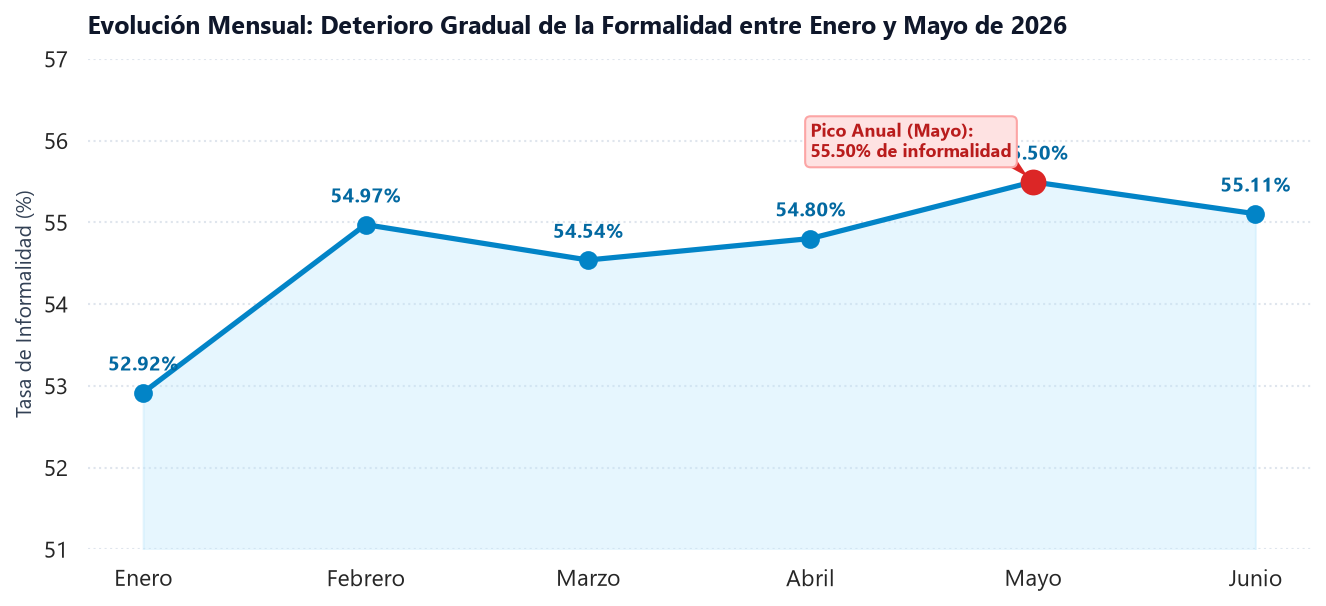

In [6]:
# GRÁFICO 3: TRAYECTORIA MENSUAL (SEABORN)

fig, ax = plt.subplots(figsize=(9, 4.2))

ax.plot(df_m["Nombre_Mes"], df_m["Tasa_Informalidad"], marker="o", color="#0284C7", linewidth=2.5, markersize=8)
ax.fill_between(df_m["Nombre_Mes"], 50, df_m["Tasa_Informalidad"], color="#BAE6FD", alpha=0.35)

for _, r in df_m.iterrows():
    ax.text(r["Nombre_Mes"], r["Tasa_Informalidad"] + 0.22, f"{r['Tasa_Informalidad']:.2f}%", ha='center', va='bottom', fontsize=9.5, fontweight='bold', color="#0369A1")

ax.scatter(["Mayo"], [55.50], color="#DC2626", s=130, zorder=5)
ax.annotate(
    "Pico Anual (Mayo):\n55.50% de informalidad",
    xy=("Mayo", 55.50), xytext=("Abril", 55.8),
    arrowprops=dict(facecolor="#DC2626", shrink=0.08, width=1.2, headwidth=6),
    fontsize=8.5, fontweight="bold", color="#B91C1C",
    bbox=dict(boxstyle="round,pad=0.3", facecolor="#FEE2E2", edgecolor="#FCA5A5")
)

ax.set_title("Evolución Mensual: Deterioro Gradual de la Formalidad entre Enero y Mayo de 2026", fontsize=12, fontweight='bold', color="#0F172A", pad=12, loc='left')
ax.set_ylabel("Tasa de Informalidad (%)", fontsize=10, color="#334155")
ax.set_ylim(51, 57)
sns.despine(left=True, bottom=True)
ax.yaxis.grid(True, linestyle=":", alpha=0.6, color="#CBD5E1")
ax.xaxis.grid(False)

plt.tight_layout()
plt.show()


**Interpretación Humana y Ciudadana (Gráfico 3):**
* **Deterioro en el primer semestre:** La tasa de informalidad nacional inició en enero en **52.92%** y subió progresivamente hasta alcanzar un pico crítico en mayo de **55.50%** (un incremento de 2.58 puntos porcentuales), cerrando en junio en 55.11%.
* **Alerta para quienes buscan empleo:** El mercado laboral no se está recuperando por inercia; la estacionalidad del segundo trimestre expulsa a más colombianos hacia la desprotección social.


## 5. Visualización Interactiva con Plotly: Explorador Ciudadano Departamental

Para que la ciudadanía pueda consultar su propio territorio, construimos un componente interactivo que clasifica los departamentos según su nivel de vulnerabilidad:
- **Alerta Crítica (> 60%):** Zonas con emergencia social y laboral.
- **Vulnerabilidad Media (50% - 60%):** En el rango promedio del país.
- **Mayor Formalidad (< 50%):** Departamentos con mayor densidad de empresas constituidas.


In [7]:
# COMPONENTE INTERACTIVO PLOTLY: EXPLORADOR DE INFORMALIDAD POR DEPARTAMENTO

df_dep_clean = df_dep[df_dep["Nombre_Departamento"] != "Desconocido"].copy()
df_dep_clean = df_dep_clean.sort_values(by="Tasa_Informalidad", ascending=True)

def clasificar_alerta(tasa):
    if tasa >= 60.0:
        return "Alerta Crítica (> 60%)"
    elif tasa >= 50.0:
        return "Vulnerabilidad Media (50% - 60%)"
    else:
        return "Mayor Formalidad (< 50%)"

df_dep_clean["Nivel_Alerta"] = df_dep_clean["Tasa_Informalidad"].apply(clasificar_alerta)

color_discrete_map = {
    "Alerta Crítica (> 60%)": "#E11D48",
    "Vulnerabilidad Media (50% - 60%)": "#F59E0B",
    "Mayor Formalidad (< 50%)": "#0284C7"
}

fig_plotly = px.bar(
    df_dep_clean,
    x="Tasa_Informalidad",
    y="Nombre_Departamento",
    orientation="h",
    color="Nivel_Alerta",
    color_discrete_map=color_discrete_map,
    custom_data=["FEX_Ocupado", "FEX_Informal", "Nivel_Alerta"],
    labels={
        "Tasa_Informalidad": "Tasa de Informalidad Laboral (%)",
        "Nombre_Departamento": "Departamento",
        "Nivel_Alerta": "Nivel de Vulnerabilidad"
    },
    title="<b>Explorador Ciudadano Interactivo: Tasa de Informalidad por Departamento (GEIH 2026)</b>"
)

fig_plotly.update_traces(
    hovertemplate=(
        "<b>%{y}</b><br>"
        "Tasa de Informalidad: <b>%{x:.2f}%</b><br>"
        "Ocupados Totales: <b>%{customdata[0]:,.0f}</b> personas<br>"
        "Informales Estimados: <b>%{customdata[1]:,.0f}</b> personas<br>"
        "Categoría: <i>%{customdata[2]}</i>"
        "<extra></extra>"
    )
)

fig_plotly.add_vline(
    x=54.64,
    line_dash="dash",
    line_color="#334155",
    annotation_text="Promedio Nacional (54.64%)",
    annotation_position="top right"
)

fig_plotly.update_layout(
    template="plotly_white",
    height=750,
    xaxis=dict(range=[0, 85], title="Tasa de Informalidad (%)", gridcolor="#F1F5F9"),
    yaxis=dict(title="", tickfont=dict(size=10)),
    legend=dict(
        orientation="h",
        yanchor="bottom",
        y=1.02,
        xanchor="right",
        x=1,
        title=dict(text="")
    ),
    margin=dict(l=150, r=30, t=90, b=40)
)

fig_plotly.show()


In [8]:
# Exportar archivo HTML interactivo para consulta ciudadana sin necesidad de Python
FIG_DIR = os.path.join("..", "figuras")
html_path = os.path.join(FIG_DIR, "visualizacion_interactiva_plotly.html")
fig_plotly.write_html(html_path, include_plotlyjs="cdn")
print(f"✓ Archivo HTML interactivo exportado exitosamente en: {html_path}")


✓ Archivo HTML interactivo exportado exitosamente en: ..\figuras\visualizacion_interactiva_plotly.html


## 6. Conclusiones y Mensaje Ciudadano Final

### 6.1. Síntesis de Hallazgos
1. **La trampa de la precarización calificada:** Estudiar más en Colombia no garantiza acceder a seguridad social. Más del **61% de los graduados de educación superior** enfrentan esquemas laborales informales o de prestación de servicios desprotegida.
2. **La lotería del código postal:** Las probabilidades de formalidad varían radicalmente según el territorio: mientras Bogotá o Antioquia tienen mayor absorción formal, departamentos como **Guaviare (75.7%)** y **Casanare (66.5%)** condenan a 3 de cada 4 trabajadores a la precariedad.
3. **El desafío de género:** La aparente menor informalidad femenina responde a una barrera de acceso previa al mercado, invisibilizando el trabajo doméstico y de cuidado no remunerado.

### 6.2. Recomendaciones Prácticas para los Nuevos Trabajadores
* **Planificación tributaria y de seguridad social:** Si te vinculas por prestación de servicios, asesórate tempranamente sobre la cotización independiente a salud y pensión sobre el 40% del valor del contrato para no perder semanas cotizadas.
* **Movilidad y teletrabajo:** Si resides en departamentos periféricos con más del 65% de informalidad, prioriza ofertas de teletrabajo vinculadas a centros urbanos o corporaciones formales.
* **Exigencia ciudadana informada:** Exigir al Estado y a las carteras de trabajo programas de formalización focalizados con subsidios a la contratación joven, en lugar de programas universales que no discriminan la realidad de cada territorio.

### 6.3. Limitaciones Metodológicas
* Los microdatos corresponden a la GEIH 2026 del DANE (primer semestre), por lo que las tasas reflejan la coyuntura del período y no permiten inferencias causales de largo plazo ni evaluación de reformas legislativas posteriores.
* La clasificación de informalidad se rige bajo la metodología DANE / OIT (cotización a salud/pensión y tamaño de establecimiento).

---
**Universidad Externado de Colombia · Facultad de Finanzas, Gobierno y Relaciones Internacionales**
